# ARCHIVO 1 — YOLO11n para góndolas: PRODUCTO / VACÍO

## Objetivo definitivo de esta etapa

Este notebook usa **solamente el dataset original de góndolas de supermercado**.

No se agregan datasets externos.

Salida final del sistema:

```text
0 = producto
1 = vacío
```

### Cómo se implementa

YOLO11 entrena una única clase real:

```text
0 = producto
```

La clase:

```text
1 = vacío
```

se calcula después mediante la geometría de las repisas: si entre dos productos de una misma fila existe un hueco suficientemente grande, se registra como espacio vacío.

Esto evita tratar el vacío como si fuera un objeto visual con forma propia.

## Dataset

Se utiliza únicamente:

```text
humansintheloop/supermarket-shelves-dataset
```

Contiene fotografías reales de góndolas con anotaciones:

- `Product`
- `Price`

En este proyecto:

```text
Product -> 0 producto
Price   -> ignorado
```

No se utilizarán datasets de frutas, verduras, botellas externas, calles, playas ni imágenes fuera del contexto de supermercado.

## RAM

Esta versión está pensada para Colab con RAM limitada:

- `imgsz=640`
- `batch=2` con GPU
- `cache=False`
- `workers=0`
- sin copias sintéticas físicas
- solo 4 imágenes en la verificación visual
- liberación explícita de memoria antes de entrenar


### Instalación de dependencias

Instala las librerías necesarias para trabajar con YOLO11, descargar el dataset público,
procesar imágenes y controlar el uso de memoria. No requiere cuentas, API keys ni Roboflow.


In [1]:
%pip install -q ultralytics kagglehub matplotlib pyyaml psutil


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 5.5 MB/s eta 0:00:00


### Configuración general

Carga las librerías principales y define la configuración del proyecto. El modelo entrena
únicamente la clase `0 = producto`; la clase `1 = vacío` se obtiene después mediante análisis
geométrico de la góndola. También se fija la resolución de entrenamiento en 640 px y los
umbrales usados para detectar espacios vacíos.


In [2]:
import os
import glob
import json
import random
import shutil
import gc
import ctypes
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import yaml
import kagglehub
import psutil

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

YOLO_WEIGHTS = "yolo11n.pt"

YOLO_NAMES = {
    0: "producto"
}

OUTPUT_NAMES = {
    0: "producto",
    1: "vacio" ####no esta mapeado el vacio
}

IMGSZ = 640
MAX_DET = 1000

ROOT = "/content/stockeye_producto_vacio"
DATASET_OUT = os.path.join(ROOT, "dataset")

MIN_GAP_PRODUCT_WIDTH = 0.90

ALERTA_VACIO = 0.50

def memoria_actual():
    proc = psutil.Process(os.getpid())
    rss = proc.memory_info().rss / (1024 ** 3)
    disp = psutil.virtual_memory().available / (1024 ** 3)

    print(
        f"RAM proceso: {rss:.2f} GB | "
        f"RAM disponible: {disp:.2f} GB"
    )

print("YOLO entrena:", YOLO_NAMES)
print("Salida final:", OUTPUT_NAMES)
print("Resolución:", IMGSZ)
memoria_actual()


YOLO entrena: {0: 'producto'}
Salida final: {0: 'producto', 1: 'vacio'}
Resolución: 640
RAM proceso: 0.16 GB | RAM disponible: 11.57 GB


### Descarga del dataset

Descarga exclusivamente el dataset original de estantes de supermercado de Humans in the Loop.
No se agregan datasets externos. La descarga se realiza con KaggleHub y no necesita una cuenta.


In [3]:
SHELVES_PATH = kagglehub.dataset_download(
    "humansintheloop/supermarket-shelves-dataset"
)

print("Dataset:")
print(SHELVES_PATH)

assert os.path.exists(SHELVES_PATH)

memoria_actual()


100%|██████████| 131M/131M [00:01<00:00, 87.4MB/s]

Extracting files...


Dataset:
/root/.cache/kagglehub/datasets/humansintheloop/supermarket-shelves-dataset/versions/2
RAM proceso: 0.16 GB | RAM disponible: 11.31 GB


### Búsqueda de imágenes y anotaciones

Recorre el dataset descargado para localizar las fotografías de góndolas y sus archivos de
anotación. Al finalizar deberían encontrarse aproximadamente 45 imágenes y sus anotaciones.


In [4]:
IMAGE_EXTS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

def listar_imagenes(root):
    rutas = []

    for carpeta, _, archivos in os.walk(root):
        for archivo in archivos:
            if archivo.lower().endswith(IMAGE_EXTS):
                rutas.append(
                    os.path.join(
                        carpeta,
                        archivo
                    )
                )

    return sorted(set(rutas))

imagenes = listar_imagenes(SHELVES_PATH)

anotaciones = []

for ext in ("json", "xml"):
    anotaciones.extend(
        glob.glob(
            os.path.join(
                SHELVES_PATH,
                "**",
                f"*.{ext}"
            ),
            recursive=True
        )
    )

anotaciones = sorted(set(anotaciones))

print("Imágenes:", len(imagenes))
print("Anotaciones:", len(anotaciones))

assert len(imagenes) >= 40
assert len(anotaciones) >= 40


Imágenes: 45
Anotaciones: 46


### Lectura de las anotaciones originales

Lee las anotaciones JSON/XML y empareja cada imagen con su archivo correspondiente. Se conservan
las categorías originales para comprobar el contenido del dataset. Posteriormente solo se usará
`Product`; las anotaciones `Price` se descartan.


In [5]:
def leer_anotacion(ruta):
    cajas = []

    if ruta.lower().endswith(".json"):
        with open(
            ruta,
            "r",
            encoding="utf-8"
        ) as f:
            data = json.load(f)

        for obj in data.get("objects", []):
            puntos = (
                obj.get("points", {})
                .get("exterior", [])
            )

            if len(puntos) < 2:
                continue

            (xa, ya), (xb, yb) = puntos[:2]

            cajas.append(
                (
                    obj.get(
                        "classTitle",
                        ""
                    ),
                    float(min(xa, xb)),
                    float(min(ya, yb)),
                    float(max(xa, xb)),
                    float(max(ya, yb))
                )
            )

    else:
        raiz = ET.parse(ruta).getroot()

        for obj in raiz.iter("object"):
            bb = obj.find("bndbox")

            if bb is None:
                continue

            cajas.append(
                (
                    obj.findtext(
                        "name",
                        default=""
                    ),
                    float(
                        bb.findtext(
                            "xmin",
                            default="0"
                        )
                    ),
                    float(
                        bb.findtext(
                            "ymin",
                            default="0"
                        )
                    ),
                    float(
                        bb.findtext(
                            "xmax",
                            default="0"
                        )
                    ),
                    float(
                        bb.findtext(
                            "ymax",
                            default="0"
                        )
                    )
                )
            )

    return cajas

indice = {}

for ann in anotaciones:
    nombre = os.path.basename(
        ann
    ).rsplit(".", 1)[0]

    indice[nombre] = ann
    indice[
        os.path.splitext(nombre)[0]
    ] = ann

pares = []

for img in imagenes:
    nombre = os.path.basename(img)

    ann = (
        indice.get(nombre)
        or indice.get(
            os.path.splitext(nombre)[0]
        )
    )

    if ann:
        pares.append((img, ann))

conteo = Counter()

for _, ann in pares:
    for clase, *_ in leer_anotacion(ann):
        conteo[str(clase)] += 1

print(
    "Imágenes con anotación:",
    len(pares)
)

print(
    "Clases originales:",
    conteo
)

assert len(pares) >= 40


Imágenes con anotación: 45
Clases originales: Counter({'Product': 9967, 'Price': 1776})


### Separación de entrenamiento, validación y prueba

Divide las imágenes antes del entrenamiento para evitar que una misma fotografía aparezca en
más de un conjunto. Con las 45 imágenes actuales se utilizan 32 para entrenamiento, 6 para
validación y 7 para prueba.


In [6]:
pares_split = pares.copy()

random.Random(SEED).shuffle(
    pares_split
)

if len(pares_split) == 45:
    splits = {
        "train": pares_split[:32],
        "val": pares_split[32:38],
        "test": pares_split[38:]
    }

else:
    n = len(pares_split)

    n_train = max(
        1,
        int(n * 0.70)
    )

    n_val = max(
        1,
        int(n * 0.15)
    )

    splits = {
        "train": (
            pares_split[:n_train]
        ),
        "val": (
            pares_split[
                n_train:
                n_train+n_val
            ]
        ),
        "test": (
            pares_split[
                n_train+n_val:
            ]
        )
    }

for split in (
    "train",
    "val",
    "test"
):
    print(
        f"{split}: "
        f"{len(splits[split])} imágenes"
    )

sets = {
    k: {x[0] for x in v}
    for k, v in splits.items()
}

assert sets["train"].isdisjoint(
    sets["val"]
)

assert sets["train"].isdisjoint(
    sets["test"]
)

assert sets["val"].isdisjoint(
    sets["test"]
)


train: 32 imágenes
val: 6 imágenes
test: 7 imágenes


### Conversión de anotaciones a formato YOLO

Convierte únicamente las cajas `Product` del dataset al formato normalizado que necesita YOLO.
Todas esas cajas reciben el ID `0 = producto`. Las etiquetas de precio no se incorporan al
entrenamiento.


In [7]:
def xyxy_a_yolo(
    caja,
    w,
    h
):
    x1, y1, x2, y2 = map(
        float,
        caja
    )

    cx = (
        (x1 + x2) / 2
    ) / w

    cy = (
        (y1 + y2) / 2
    ) / h

    bw = (
        x2 - x1
    ) / w

    bh = (
        y2 - y1
    ) / h

    return (
        float(np.clip(cx, 0, 1)),
        float(np.clip(cy, 0, 1)),
        float(np.clip(bw, 0, 1)),
        float(np.clip(bh, 0, 1))
    )

def productos_desde_anotacion(
    ann_path
):
    cajas = []

    for (
        clase,
        x1,
        y1,
        x2,
        y2
    ) in leer_anotacion(
        ann_path
    ):

        if (
            str(clase).lower()
            == "product"
            and x2 > x1
            and y2 > y1
        ):
            cajas.append(
                [
                    x1,
                    y1,
                    x2,
                    y2
                ]
            )

    return cajas

def guardar_labels(
    txt_path,
    cajas,
    w,
    h
):
    with open(
        txt_path,
        "w",
        encoding="utf-8"
    ) as f:

        for caja in cajas:
            (
                cx,
                cy,
                bw,
                bh
            ) = xyxy_a_yolo(
                caja,
                w,
                h
            )

            f.write(
                f"0 "
                f"{cx:.6f} "
                f"{cy:.6f} "
                f"{bw:.6f} "
                f"{bh:.6f}\n"
            )


### Creación del dataset de entrenamiento

Construye las carpetas `train`, `val` y `test` que utilizará YOLO. Las fotografías se reducen
de tamaño antes de guardarlas para disminuir el consumo de RAM, y las coordenadas de las cajas
se ajustan a la nueva resolución.


In [8]:
if os.path.exists(
    DATASET_OUT
):
    shutil.rmtree(
        DATASET_OUT
    )

for split in (
    "train",
    "val",
    "test"
):
    os.makedirs(
        os.path.join(
            DATASET_OUT,
            "images",
            split
        ),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(
            DATASET_OUT,
            "labels",
            split
        ),
        exist_ok=True
    )

def guardar_imagen_optimizada(
    src,
    dst,
    max_side=960
):
    img = cv2.imread(src)

    if img is None:
        return None

    h, w = img.shape[:2]

    lado = max(h, w)

    if lado > max_side:
        escala = (
            max_side / lado
        )

        nw = max(
            1,
            int(round(w * escala))
        )

        nh = max(
            1,
            int(round(h * escala))
        )

        img = cv2.resize(
            img,
            (nw, nh),
            interpolation=cv2.INTER_AREA
        )

    cv2.imwrite(
        dst,
        img,
        [
            int(
                cv2.IMWRITE_JPEG_QUALITY
            ),
            88
        ]
    )

    nuevo_h, nuevo_w = (
        img.shape[:2]
    )

    del img

    return nuevo_w, nuevo_h

for split, items in splits.items():
    total_productos = 0

    for idx, (
        img_path,
        ann_path
    ) in enumerate(items):

        cajas = (
            productos_desde_anotacion(
                ann_path
            )
        )

        if not cajas:
            continue

        nombre = (
            f"{split}_{idx:03d}"
        )

        out_img = os.path.join(
            DATASET_OUT,
            "images",
            split,
            nombre + ".jpg"
        )

        out_lbl = os.path.join(
            DATASET_OUT,
            "labels",
            split,
            nombre + ".txt"
        )

        tamaño = (
            guardar_imagen_optimizada(
                img_path,
                out_img
            )
        )

        if tamaño is None:
            continue

        w, h = tamaño

        original = cv2.imread(
            img_path
        )

        oh, ow = original.shape[:2]

        del original

        sx = w / ow
        sy = h / oh

        cajas_escaladas = [
            [
                x1 * sx,
                y1 * sy,
                x2 * sx,
                y2 * sy
            ]
            for x1, y1, x2, y2
            in cajas
        ]

        guardar_labels(
            out_lbl,
            cajas_escaladas,
            w,
            h
        )

        total_productos += len(
            cajas_escaladas
        )

    print(
        f"{split}: "
        f"{total_productos} productos"
    )

memoria_actual()


train: 6485 productos
val: 1253 productos
test: 2186 productos
RAM proceso: 0.20 GB | RAM disponible: 11.12 GB


### Validación de etiquetas

Comprueba que todas las etiquetas tengan el ID correcto y que las coordenadas YOLO estén dentro
del rango válido. La ejecución debe terminar con `0 errores` en entrenamiento, validación y prueba.


In [9]:
def leer_yolo(
    txt_path
):
    filas = []

    if not os.path.exists(
        txt_path
    ):
        return filas

    with open(
        txt_path,
        "r",
        encoding="utf-8"
    ) as f:

        for linea in f:
            p = (
                linea
                .strip()
                .split()
            )

            if len(p) != 5:
                continue

            filas.append(
                (
                    int(
                        float(p[0])
                    ),
                    float(p[1]),
                    float(p[2]),
                    float(p[3]),
                    float(p[4])
                )
            )

    return filas

for split in (
    "train",
    "val",
    "test"
):
    labels_dir = os.path.join(
        DATASET_OUT,
        "labels",
        split
    )

    archivos = glob.glob(
        os.path.join(
            labels_dir,
            "*.txt"
        )
    )

    objetos = 0
    errores = 0

    for txt in archivos:
        for (
            cls,
            cx,
            cy,
            bw,
            bh
        ) in leer_yolo(txt):

            objetos += 1

            if cls != 0:
                errores += 1

            if not (
                0 <= cx <= 1
                and 0 <= cy <= 1
                and 0 < bw <= 1
                and 0 < bh <= 1
            ):
                errores += 1

    print(
        f"{split}: "
        f"{len(archivos)} imágenes | "
        f"{objetos} productos | "
        f"{errores} errores"
    )

    assert errores == 0


train: 32 imágenes | 6485 productos | 0 errores
val: 6 imágenes | 1253 productos | 0 errores
test: 7 imágenes | 2186 productos | 0 errores


### Configuración del dataset para YOLO

Genera el archivo `data.yaml` que indica a Ultralytics dónde están las imágenes y que existe una
sola clase entrenada: `producto`.


In [10]:
yaml_path = os.path.join(
    DATASET_OUT,
    "data.yaml"
)

data_yaml = {
    "path": DATASET_OUT,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "producto"
    }
}

with open(
    yaml_path,
    "w",
    encoding="utf-8"
) as f:

    yaml.safe_dump(
        data_yaml,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print(
    open(
        yaml_path,
        "r",
        encoding="utf-8"
    ).read()
)


path: /content/stockeye_producto_vacio/dataset
train: images/train
val: images/val
test: images/test
names:
  0: producto



### Comprobación visual de las etiquetas

Muestra cuatro imágenes del conjunto de entrenamiento con sus bounding boxes. Esta revisión sirve
para confirmar que las cajas realmente cubren productos de la góndola antes de gastar tiempo en
el entrenamiento.


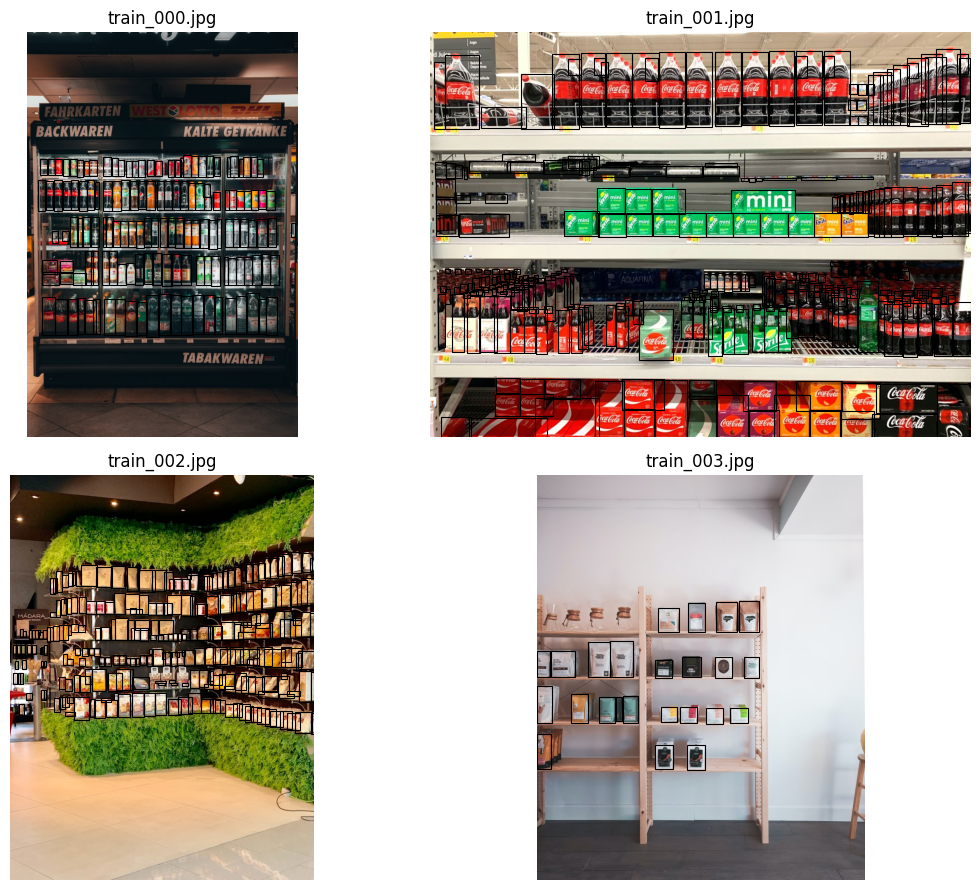

RAM proceso: 0.21 GB | RAM disponible: 11.11 GB


In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def yolo_a_xyxy(
    cx,
    cy,
    bw,
    bh,
    w,
    h
):
    x1 = (
        cx - bw/2
    ) * w

    y1 = (
        cy - bh/2
    ) * h

    x2 = (
        cx + bw/2
    ) * w

    y2 = (
        cy + bh/2
    ) * h

    return (
        x1,
        y1,
        x2,
        y2
    )

muestras = sorted(
    glob.glob(
        os.path.join(
            DATASET_OUT,
            "images",
            "train",
            "*.jpg"
        )
    )
)[:4]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)

axes = np.array(
    axes
).ravel()

for ax, img_path in zip(
    axes,
    muestras
):
    img = cv2.imread(
        img_path
    )

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    h, w = img.shape[:2]

    txt = os.path.join(
        DATASET_OUT,
        "labels",
        "train",
        Path(img_path).stem
        + ".txt"
    )

    ax.imshow(img)

    for (
        _,
        cx,
        cy,
        bw,
        bh
    ) in leer_yolo(txt):

        (
            x1,
            y1,
            x2,
            y2
        ) = yolo_a_xyxy(
            cx,
            cy,
            bw,
            bh,
            w,
            h
        )

        ax.add_patch(
            patches.Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                linewidth=0.8
            )
        )

    ax.set_title(
        Path(img_path).name
    )

    ax.axis("off")

    del img

plt.tight_layout()
plt.show()
plt.close(fig)

gc.collect()

memoria_actual()


## Revisión antes de entrenar

En las cuatro imágenes anteriores deberías ver bounding boxes únicamente sobre productos de la góndola.

No deberían aparecer cajas sobre:

- precios,
- estantes,
- fondo,
- personas.

Si las cajas se ven razonables, continúa.


### Liberación de memoria

Elimina variables que ya no se necesitan y solicita al sistema liberar memoria antes de cargar
PyTorch y YOLO11. Esta parte está orientada a evitar los reinicios de Colab por falta de RAM.


In [12]:
print(
    "Antes de liberar memoria:"
)

memoria_actual()

for nombre in [
    "imagenes",
    "anotaciones",
    "indice",
    "pares",
    "pares_split"
]:
    if nombre in globals():
        try:
            del globals()[nombre]
        except Exception:
            pass

gc.collect()

try:
    ctypes.CDLL(
        "libc.so.6"
    ).malloc_trim(0)
except Exception:
    pass

print(
    "\nDespués de liberar memoria:"
)

memoria_actual()


Antes de liberar memoria:
RAM proceso: 0.21 GB | RAM disponible: 11.11 GB

Después de liberar memoria:
RAM proceso: 0.18 GB | RAM disponible: 11.12 GB


### Entrenamiento de YOLO11n

Entrena YOLO11n para detectar `0 = producto`. La configuración utiliza resolución 640, batch
pequeño, sin caché en RAM y sin procesos adicionales de carga para mantener bajo el consumo de
memoria en una GPU T4 de Colab.


In [13]:
import torch
from ultralytics import YOLO

device_used = (
    0
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "GPU disponible:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

memoria_actual()

batch_used = (
    2
    if torch.cuda.is_available()
    else 1
)

model = YOLO(
    YOLO_WEIGHTS
)

results = model.train(
    data=yaml_path,

    epochs=50,
    patience=10,

    imgsz=IMGSZ,
    batch=batch_used,
    device=device_used,

    optimizer="AdamW",
    lr0=0.001,#########################################################################
    lrf=0.1,
    cos_lr=True,
    warmup_epochs=3,

    mosaic=0.20,
    close_mosaic=8,
    mixup=0.0,

    fliplr=0.5,
    flipud=0.0,

    degrees=3.0,
    translate=0.06,
    scale=0.15,
    perspective=0.0003,

    hsv_h=0.015,
    hsv_s=0.30,
    hsv_v=0.25,

    max_det=MAX_DET,

    cache=False,
    workers=0,
    amp=True,
    seed=SEED,

    plots=False,
    save=True,
    val=True,
    verbose=True,

    project="/content/runs",
    name="stockeye_producto",
    exist_ok=True
)

BEST = os.path.join(
    str(
        model.trainer.save_dir
    ),
    "weights",
    "best.pt"
)

print(
    "\nMejor modelo:"
)

print(BEST)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU disponible: True
GPU: Tesla T4
RAM proceso: 0.64 GB | RAM disponible: 10.87 GB
Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/stockeye_producto_vacio/dataset/data.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=No

### Evaluación del detector de productos

Evalúa el mejor modelo sobre las 7 imágenes de test que no participaron del entrenamiento.
Muestra Precision, Recall, mAP50 y mAP50-95. La meta inicial establecida para esta fase es lograr
al menos 50% de Precision en la detección de productos.


In [14]:
best_model = YOLO(
    BEST
)

metrics = best_model.val(
    data=yaml_path,
    split="test",
    imgsz=IMGSZ,
    max_det=MAX_DET,
    device=device_used,
    verbose=False
)

print(
    "\n"
    + "=" * 72
)

print(
    "RESULTADOS PRODUCTO"
)

print(
    "=" * 72
)

print(
    f"Precision : "
    f"{metrics.box.mp:.1%}"
)

print(
    f"Recall    : "
    f"{metrics.box.mr:.1%}"
)

print(
    f"mAP50     : "
    f"{metrics.box.map50:.3f}"
)

print(
    f"mAP50-95  : "
    f"{metrics.box.map:.3f}"
)

if metrics.box.mp >= 0.50:
    print(
        "\nMETA INICIAL 50%: CUMPLIDA"
    )
else:
    print(
        "\nMETA INICIAL 50%: "
        "TODAVÍA NO CUMPLIDA"
    )


Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2685.9±237.1 MB/s, size: 252.2 KB)
val: Scanning /content/stockeye_producto_vacio/dataset/labels/test... 7 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7/7 724.4it/s 0.0s
val: /content/stockeye_producto_vacio/dataset/images/test/test_006.jpg: 1 duplicate labels removed
val: New cache created: /content/stockeye_producto_vacio/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.5it/s 0.3s
                   all          7       2185      0.501      0.414      0.346      0.152
Speed: 0.4ms preprocess, 12.0ms inference, 0.0ms loss, 3.9ms postprocess per image
Results saved to /content/runs/detect/val

RESULTADOS PRODUCTO
Precision : 50.1%
Recall    : 41.4%
mAP50     : 0.346
mAP50-95 

### Calibración para acercarse al 70% de Precision

Antes de cambiar el modelo o agregar datos, se calibra el umbral de confianza usando únicamente el
conjunto de validación. Se prueban varios valores de `conf` y se calculan manualmente Precision y Recall
con IoU 0.50.

El objetivo es encontrar el umbral que logre aproximadamente `Precision >= 70%` conservando el mayor
Recall posible. Después, ese mismo valor se evalúa una sola vez sobre el conjunto de test.

Esto no modifica los pesos del modelo. Ajusta el punto de operación. Si la Precision sube a costa de un
Recall demasiado bajo, el gráfico lo hará visible y no se considerará una mejora suficiente.


In [15]:
def yolo_label_a_xyxy(
    cx,
    cy,
    bw,
    bh,
    w,
    h
):
    return np.array(
        [
            (cx - bw / 2) * w,
            (cy - bh / 2) * h,
            (cx + bw / 2) * w,
            (cy + bh / 2) * h
        ],
        dtype=np.float32
    )


def iou_box(
    a,
    b
):
    ix1 = max(
        float(a[0]),
        float(b[0])
    )

    iy1 = max(
        float(a[1]),
        float(b[1])
    )

    ix2 = min(
        float(a[2]),
        float(b[2])
    )

    iy2 = min(
        float(a[3]),
        float(b[3])
    )

    iw = max(
        0.0,
        ix2 - ix1
    )

    ih = max(
        0.0,
        iy2 - iy1
    )

    inter = iw * ih

    area_a = max(
        0.0,
        float(a[2] - a[0])
    ) * max(
        0.0,
        float(a[3] - a[1])
    )

    area_b = max(
        0.0,
        float(b[2] - b[0])
    ) * max(
        0.0,
        float(b[3] - b[1])
    )

    union = (
        area_a
        + area_b
        - inter
    )

    return (
        inter / union
        if union > 0
        else 0.0
    )


def evaluar_conf_manual(
    modelo,
    split,
    conf,
    iou_match=0.50
):
    img_dir = os.path.join(
        DATASET_OUT,
        "images",
        split
    )

    lbl_dir = os.path.join(
        DATASET_OUT,
        "labels",
        split
    )

    rutas = sorted(
        glob.glob(
            os.path.join(
                img_dir,
                "*.jpg"
            )
        )
    )

    tp = 0
    fp = 0
    fn = 0

    por_imagen = []

    for img_path in rutas:
        img = cv2.imread(
            img_path
        )

        if img is None:
            continue

        h, w = img.shape[:2]

        lbl_path = os.path.join(
            lbl_dir,
            Path(img_path).stem
            + ".txt"
        )

        gt = []

        for (
            cls,
            cx,
            cy,
            bw,
            bh
        ) in leer_yolo(
            lbl_path
        ):
            if cls == 0:
                gt.append(
                    yolo_label_a_xyxy(
                        cx,
                        cy,
                        bw,
                        bh,
                        w,
                        h
                    )
                )

        pred = modelo.predict(
            img,
            imgsz=IMGSZ,
            conf=conf,
            max_det=MAX_DET,
            device=device_used,
            verbose=False
        )[0]

        if (
            pred.boxes is not None
            and len(pred.boxes) > 0
        ):
            pred_boxes = (
                pred.boxes
                .xyxy
                .detach()
                .cpu()
                .numpy()
            )

            pred_confs = (
                pred.boxes
                .conf
                .detach()
                .cpu()
                .numpy()
            )

            orden = np.argsort(
                -pred_confs
            )

            pred_boxes = (
                pred_boxes[orden]
            )

        else:
            pred_boxes = np.empty(
                (0, 4),
                dtype=np.float32
            )

        usados = set()
        tp_img = 0
        fp_img = 0

        for caja_pred in pred_boxes:
            mejor_iou = 0.0
            mejor_idx = None

            for idx_gt, caja_gt in enumerate(
                gt
            ):
                if idx_gt in usados:
                    continue

                valor = iou_box(
                    caja_pred,
                    caja_gt
                )

                if valor > mejor_iou:
                    mejor_iou = valor
                    mejor_idx = idx_gt

            if (
                mejor_idx is not None
                and mejor_iou >= iou_match
            ):
                tp += 1
                tp_img += 1
                usados.add(
                    mejor_idx
                )
            else:
                fp += 1
                fp_img += 1

        fn_img = (
            len(gt)
            - len(usados)
        )

        fn += fn_img

        por_imagen.append(
            {
                "imagen": Path(
                    img_path
                ).name,
                "tp": tp_img,
                "fp": fp_img,
                "fn": fn_img
            }
        )

        del img
        del pred

    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else 0.0
    )

    f1 = (
        2
        * precision
        * recall
        / (
            precision
            + recall
        )
        if precision + recall > 0
        else 0.0
    )

    return {
        "conf": float(conf),
        "precision": float(
            precision
        ),
        "recall": float(
            recall
        ),
        "f1": float(f1),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "por_imagen": por_imagen
    }


conf_candidatos = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.60,
    0.70
]

resultados_calibracion = []

for conf in conf_candidatos:
    resultado_conf = (
        evaluar_conf_manual(
            modelo=best_model,
            split="val",
            conf=conf,
            iou_match=0.50
        )
    )

    resultados_calibracion.append(
        resultado_conf
    )

    print(
        f"conf={conf:.2f} | "
        f"P={resultado_conf['precision']:.1%} | "
        f"R={resultado_conf['recall']:.1%} | "
        f"F1={resultado_conf['f1']:.1%}"
    )


candidatos_70 = [
    x
    for x
    in resultados_calibracion
    if x["precision"] >= 0.70
    and x["recall"] >= 0.20
]

if candidatos_70:
    mejor_calibracion = max(
        candidatos_70,
        key=lambda x: (
            x["recall"],
            x["f1"]
        )
    )
else:
    mejor_calibracion = max(
        resultados_calibracion,
        key=lambda x: (
            x["f1"],
            x["precision"]
        )
    )


CONF_PRODUCTO_CALIBRADO = float(
    mejor_calibracion["conf"]
)


resultado_test_calibrado = (
    evaluar_conf_manual(
        modelo=best_model,
        split="test",
        conf=CONF_PRODUCTO_CALIBRADO,
        iou_match=0.50
    )
)


print(
    "\nUmbral elegido:",
    CONF_PRODUCTO_CALIBRADO
)

print(
    "Validación | "
    f"P={mejor_calibracion['precision']:.1%} | "
    f"R={mejor_calibracion['recall']:.1%}"
)

print(
    "Test       | "
    f"P={resultado_test_calibrado['precision']:.1%} | "
    f"R={resultado_test_calibrado['recall']:.1%}"
)

if resultado_test_calibrado[
    "precision"
] >= 0.70:
    print(
        "META 70% DE PRECISION: "
        "CUMPLIDA EN TEST"
    )
else:
    print(
        "META 70% DE PRECISION: "
        "AÚN NO CUMPLIDA EN TEST"
    )


conf=0.10 | P=51.1% | R=50.2% | F1=50.7%
conf=0.15 | P=57.4% | R=46.0% | F1=51.1%
conf=0.20 | P=62.5% | R=43.2% | F1=51.1%
conf=0.25 | P=67.1% | R=40.4% | F1=50.4%
conf=0.30 | P=70.4% | R=39.3% | F1=50.4%
conf=0.35 | P=73.6% | R=36.6% | F1=48.9%
conf=0.40 | P=76.3% | R=33.9% | F1=47.0%
conf=0.45 | P=78.7% | R=32.2% | F1=45.7%
conf=0.50 | P=81.6% | R=30.2% | F1=44.1%
conf=0.60 | P=84.0% | R=26.0% | F1=39.7%
conf=0.70 | P=87.5% | R=21.8% | F1=34.9%

Umbral elegido: 0.3
Validación | P=70.4% | R=39.3%
Test       | P=63.8% | R=25.8%
META 70% DE PRECISION: AÚN NO CUMPLIDA EN TEST


### Detección de espacios vacíos dentro de la góndola

Implementa la segunda etapa del sistema. Primero agrupa los productos por nivel de repisa e intenta
detectar las líneas horizontales del estante. Después calcula zonas libres al inicio, entre productos
y al final de cada repisa. Cada posible vacío se revisa nuevamente con YOLO a una confianza más baja
para reducir falsos vacíos causados por productos que la primera detección pudo omitir.

El resultado usa `1 = vacío`. El valor mostrado para el vacío es un score geométrico y no una
probabilidad producida directamente por YOLO.


Imágenes de test: 7


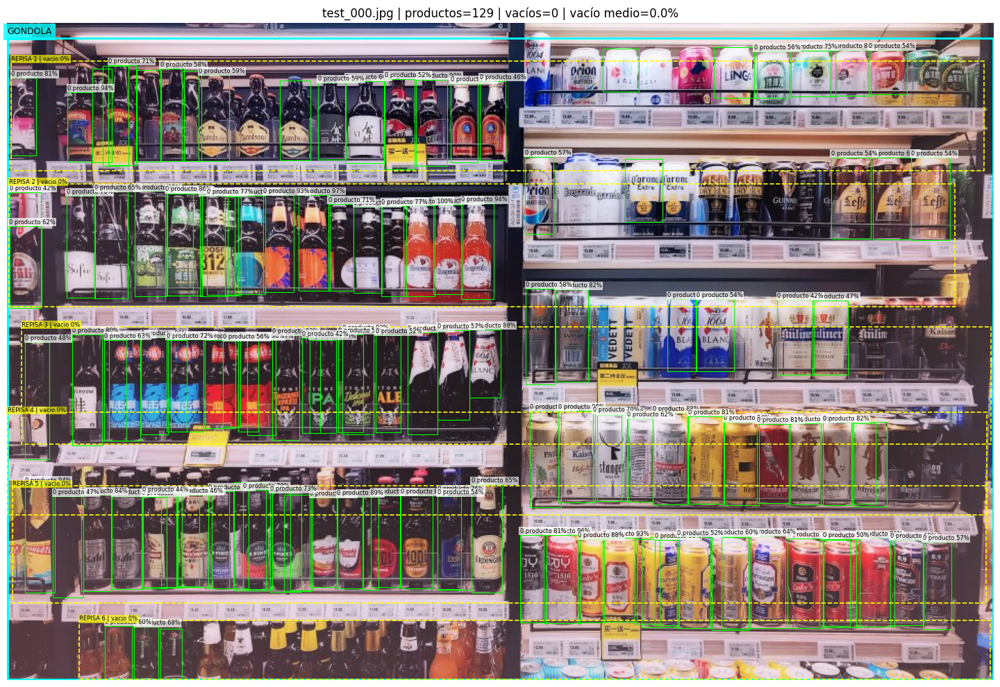


 test_000.jpg
  Repisa 1: 22 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 2: 24 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 3: 30 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 4: 10 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 5: 40 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 6: 3 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa


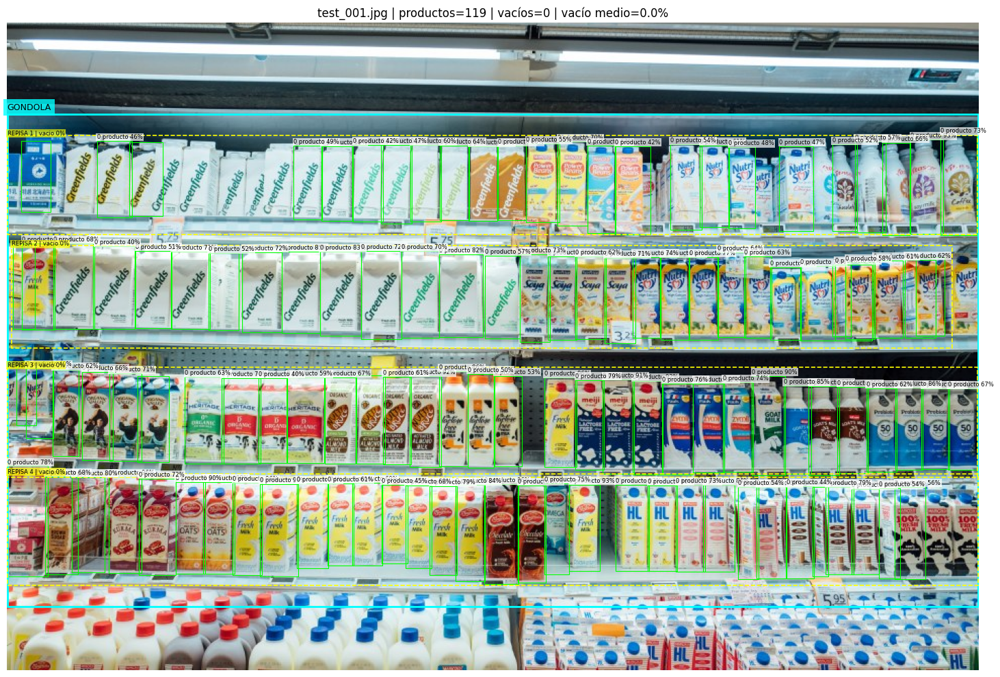


 test_001.jpg
  Repisa 1: 24 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 2: 31 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 3: 32 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 4: 32 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa


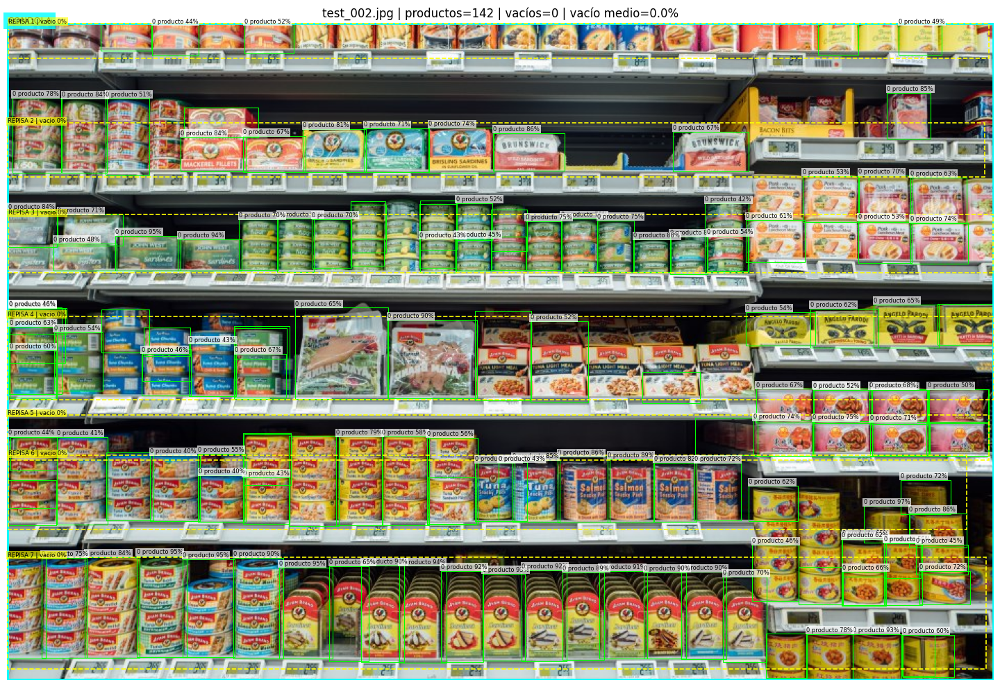


 test_002.jpg
  Repisa 1: 5 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 2: 12 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 3: 31 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 4: 23 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 5: 16 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 6: 23 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 7: 32 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa


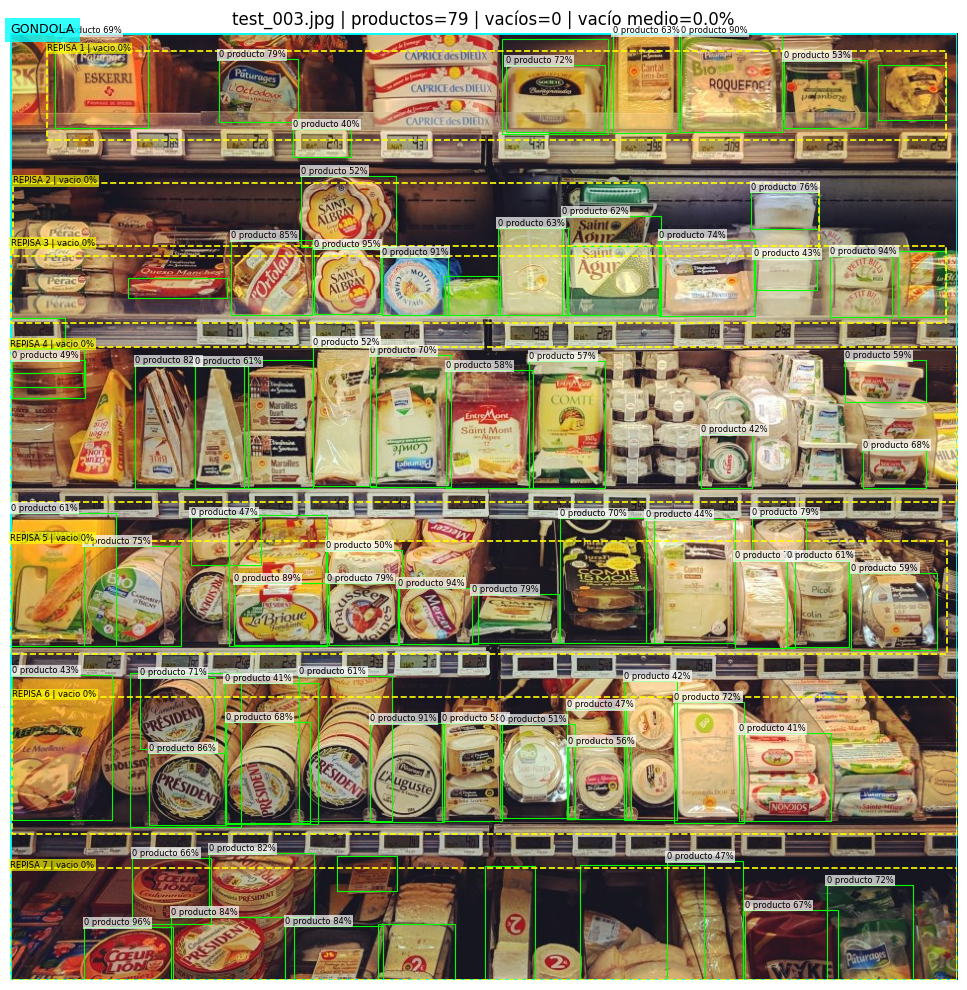


 test_003.jpg
  Repisa 1: 9 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 2: 3 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 3: 12 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 4: 13 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 5: 15 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 6: 15 productos | 0 vacíos | 0.0% vacío | límites=linea_repisa
  Repisa 7: 12 productos | 0 vacíos | 0.0% vacío | límites=estimado


In [18]:
import gc
import matplotlib.pyplot as plt
import matplotlib.patches as patches

test_images = sorted(
    glob.glob(
        os.path.join(
            DATASET_OUT,
            "images",
            "test",
            "*.jpg"
        )
    )
)

print(
    "Imágenes de test:",
    len(test_images)
)

resumen_vacios = []

for img_path in test_images[:4]:

    img_bgr = cv2.imread(
        img_path
    )

    if img_bgr is None:
        continue

    pred = best_model.predict(
        img_bgr,
        imgsz=IMGSZ,
        conf=CONF_PRODUCTO,
        max_det=MAX_DET,
        device=device_used,
        verbose=False
    )[0]

    if (
        pred.boxes is not None
        and len(pred.boxes) > 0
    ):
        cajas = (
            pred.boxes
            .xyxy
            .detach()
            .cpu()
            .numpy()
        )

        confs = (
            pred.boxes
            .conf
            .detach()
            .cpu()
            .numpy()
        )

    else:
        cajas = np.empty(
            (0, 4),
            dtype=np.float32
        )

        confs = np.array(
            [],
            dtype=np.float32
        )

    resultado = (
        calculador_vacios.calcular(
            img_bgr=img_bgr,
            cajas=cajas,
            modelo=best_model,
            device=device_used
        )
    )

    img_rgb = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2RGB
    )

    fig, ax = plt.subplots(
        figsize=(16, 10)
    )

    ax.imshow(
        img_rgb
    )

    for caja, conf in zip(
        cajas,
        confs
    ):
        (
            x1,
            y1,
            x2,
            y2
        ) = caja

        ax.add_patch(
            patches.Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor="lime",
                linewidth=0.8
            )
        )

        if conf >= 0.40:
            ax.text(
                x1,
                max(0, y1-2),
                (
                    "0 producto "
                    f"{conf:.0%}"
                ),
                fontsize=6,
                color="black",
                bbox=dict(
                    facecolor="white",
                    alpha=0.70,
                    edgecolor="none",
                    pad=1
                )
            )


    if resultado[
        "gondola_bbox"
    ] is not None:
        (
            gx1,
            gy1,
            gx2,
            gy2
        ) = resultado[
            "gondola_bbox"
        ]

        ax.add_patch(
            patches.Rectangle(
                (gx1, gy1),
                gx2-gx1,
                gy2-gy1,
                fill=False,
                edgecolor="cyan",
                linewidth=2.0
            )
        )

        ax.text(
            gx1,
            max(
                0,
                gy1 - 4
            ),
            "GONDOLA",
            fontsize=9,
            color="black",
            bbox=dict(
                facecolor="cyan",
                alpha=0.80,
                edgecolor="none"
            )
        )

    for nivel in resultado[
        "niveles"
    ]:
        x1 = nivel["x_inicio"]
        x2 = nivel["x_fin"]

        y = nivel["y_bottom"]

        y1_repisa = nivel[
            "y_top"
        ]

        y2_repisa = nivel[
            "y_bottom"
        ]

        ax.add_patch(
            patches.Rectangle(
                (
                    x1,
                    y1_repisa
                ),
                x2-x1,
                y2_repisa-y1_repisa,
                fill=False,
                edgecolor="yellow",
                linewidth=1.2,
                linestyle="--"
            )
        )

        ax.text(
            x1,
            y1_repisa,
            (
                f"REPISA {nivel['nivel']} | "
                f"vacio {nivel['vacio']:.0%}"
            ),
            fontsize=6,
            color="black",
            bbox=dict(
                facecolor="yellow",
                alpha=0.65,
                edgecolor="none",
                pad=1
            )
        )

    for gap in resultado[
        "vacios"
    ]:
        (
            x1,
            y1,
            x2,
            y2
        ) = gap["bbox"]

        ax.add_patch(
            patches.Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                facecolor="red",
                edgecolor="red",
                alpha=0.28,
                linewidth=1.5
            )
        )

        ax.text(
            x1,
            y1,
            (
                "1 vacio "
                f"{gap['score_geometrico']:.0%}"
            ),
            fontsize=7,
            color="white",
            bbox=dict(
                facecolor="red",
                alpha=0.85,
                edgecolor="none",
                pad=1
            )
        )

    ax.set_title(
        (
            f"{Path(img_path).name} | "
            f"productos={len(cajas)} | "
            f"vacíos={len(resultado['vacios'])} | "
            f"vacío medio={resultado['vacio_total']:.1%}"
        ),
        fontsize=12
    )

    ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print(
        "\n",
        Path(img_path).name
    )

    for nivel in resultado[
        "niveles"
    ]:
        print(
            f"  Repisa {nivel['nivel']}: "
            f"{nivel['productos']} productos | "
            f"{len(nivel['gaps'])} vacíos | "
            f"{nivel['vacio']:.1%} vacío | "
            f"límites={nivel['limite_repisa']}"
        )

    resumen_vacios.append(
        {
            "imagen": Path(img_path).name,
            "productos_detectados": int(len(cajas)),
            "vacios_detectados": int(len(resultado["vacios"])),
            "vacio_estimado": float(resultado["vacio_total"] * 100.0)
        }
    )

    del pred
    del img_bgr
    del img_rgb
    del cajas
    del confs

    gc.collect()

    try:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


### Gráfico 1 — Porcentaje de logro del detector

Resume las métricas principales obtenidas en el conjunto de prueba: Precision, Recall, mAP50 y
mAP50-95. La línea del 50% corresponde a la meta inicial definida para esta etapa.

Este gráfico permite ver de inmediato qué métricas ya alcanzan el objetivo y cuáles todavía necesitan
mejorar. Precision mide cuántas detecciones realizadas fueron correctas, mientras que Recall mide
cuántos de los productos reales consiguió encontrar el modelo.


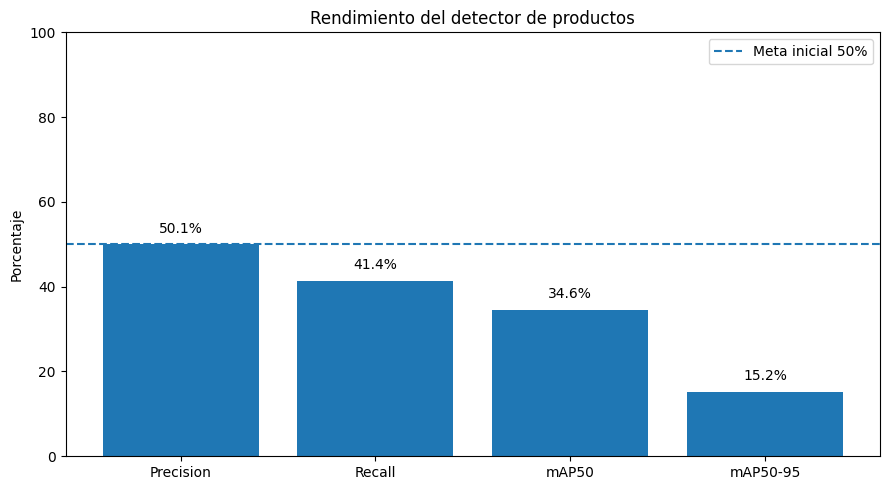

In [19]:
import matplotlib.pyplot as plt

metricas_nombres = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

metricas_valores = [
    float(metrics.box.mp) * 100,
    float(metrics.box.mr) * 100,
    float(metrics.box.map50) * 100,
    float(metrics.box.map) * 100
]

fig, ax = plt.subplots(
    figsize=(9, 5)
)

barras = ax.bar(
    metricas_nombres,
    metricas_valores
)

ax.axhline(
    50,
    linestyle="--",
    linewidth=1.5,
    label="Meta inicial 50%"
)

ax.set_ylim(
    0,
    100
)

ax.set_ylabel(
    "Porcentaje"
)

ax.set_title(
    "Rendimiento del detector de productos"
)

for barra, valor in zip(
    barras,
    metricas_valores
):
    ax.text(
        barra.get_x()
        + barra.get_width() / 2,
        valor + 2,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)


### Gráfico 2 — Principales fallas del detector

Muestra dos fuentes de error derivadas de las métricas del modelo.

`Detecciones incorrectas` corresponde a `100 - Precision`: representa la proporción aproximada de
detecciones realizadas que no coincidieron correctamente con un producto.

`Productos omitidos` corresponde a `100 - Recall`: representa la proporción de productos reales que
el modelo no consiguió encontrar. Este segundo valor es especialmente importante porque una omisión
puede hacer que el algoritmo de vacío interprete una zona ocupada como libre.


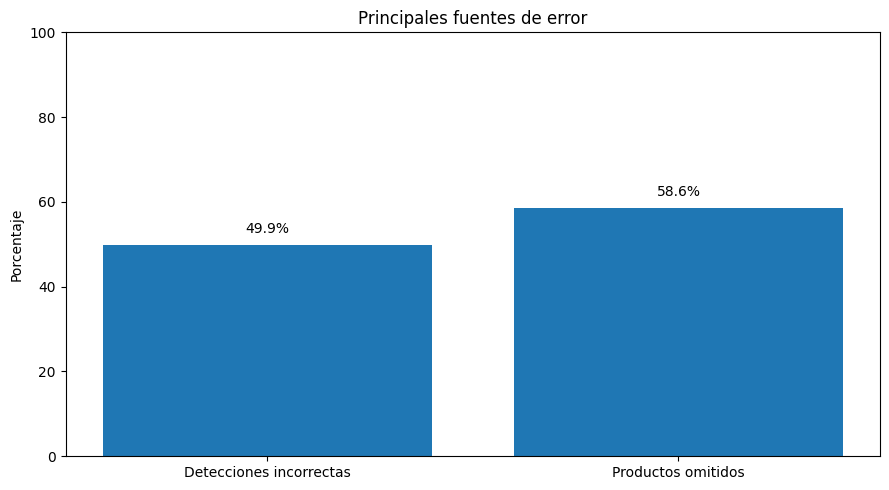

In [20]:
precision_pct = float(
    metrics.box.mp
) * 100

recall_pct = float(
    metrics.box.mr
) * 100

fallas_nombres = [
    "Detecciones incorrectas",
    "Productos omitidos"
]

fallas_valores = [
    100 - precision_pct,
    100 - recall_pct
]

fig, ax = plt.subplots(
    figsize=(9, 5)
)

barras = ax.bar(
    fallas_nombres,
    fallas_valores
)

ax.set_ylim(
    0,
    100
)

ax.set_ylabel(
    "Porcentaje"
)

ax.set_title(
    "Principales fuentes de error"
)

for barra, valor in zip(
    barras,
    fallas_valores
):
    ax.text(
        barra.get_x()
        + barra.get_width() / 2,
        valor + 2,
        f"{valor:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()
plt.close(fig)


In [22]:
MODEL_EXPORT = (
    "/content/"
    "best_stockeye_producto.pt"
)

shutil.copy2(
    BEST,
    MODEL_EXPORT
)

metadata = {
    "model": "YOLO11n",

    "output_classes": {
        "0": "producto",
        "1": "vacio"
    },

    "trained_classes": {
        "0": "producto"
    },

    "derived_classes": {
        "1": "vacio"
    },

    "imgsz": IMGSZ,

    "precision_producto": float(
        metrics.box.mp
    ),

    "recall_producto": float(
        metrics.box.mr
    ),

    "map50_producto": float(
        metrics.box.map50
    ),
    "empty_detection": "shelf_geometry_v2_two_pass",
    "empty_id": 1,
    "product_id": 0,
    "gap_min_product_width_ratio": MIN_GAP_PRODUCT_WIDTH,
    "gap_recheck_conf": CONF_RECHECK,
    "conf_producto_calibrado": float(CONF_PRODUCTO_CALIBRADO),
    "precision_test_calibrada": float(resultado_test_calibrado["precision"]),
    "recall_test_calibrado": float(resultado_test_calibrado["recall"])
}

METADATA_EXPORT = (
    "/content/"
    "stockeye_producto_vacio.json"
)

with open(
    METADATA_EXPORT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

print(
    "Modelo listo:"
)

print(
    MODEL_EXPORT
)

print(
    "\nConfiguración:"
)

print(
    METADATA_EXPORT
)

print(
    "\nIDs finales:"
)

print(
    "0 = producto"
)

print(
    "1 = vacio"
)


Modelo listo:
/content/best_stockeye_producto.pt

Configuración:
/content/stockeye_producto_vacio.json

IDs finales:
0 = producto
1 = vacio
